# Flow-JEPA: sampling latent futures

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/flowjepa.ipynb)

[Flow-JEPA](https://arxiv.org/abs/2608.29029) ([code](https://github.com/HuoYanchen/Flow-JEPA)) keeps LeWM's encoder and SIGReg, and replaces its predictor with a flow-matching model of the future: from the current embedding and the next actions, it turns Gaussian noise into the next five embeddings. Each draw of the noise is a different imagined future.

Here a macaw learns to fly a sky split by a rock wall with one gap, where a push toward the wall may or may not go through.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import Macaw
from torch_world.models import FlowJEPA
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
SKIP = 5  # the model sees every 5th frame and the 5 actions in between

## Data and model
The macaw flies at random, with no goal in mind, through a sky split by a rock wall with one gap. A small ViT embeds each frame, and a transformer, conditioned on the flow time, denoises the five future embeddings together.

In [3]:
data = Macaw(batch_size=1024, rooms=True, device=device).collect(40, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=6, frameskip=SKIP), batch_size=128, shuffle=True, drop_last=True)

encoder = CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)
model = FlowJEPA(encoder, action_dim=2 * SKIP, embed_dim=128, num_preds=5, depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

2.4M parameters


## Train
Flow matching on the straight path from noise to the future embeddings, plus SIGReg, end to end from pixels.

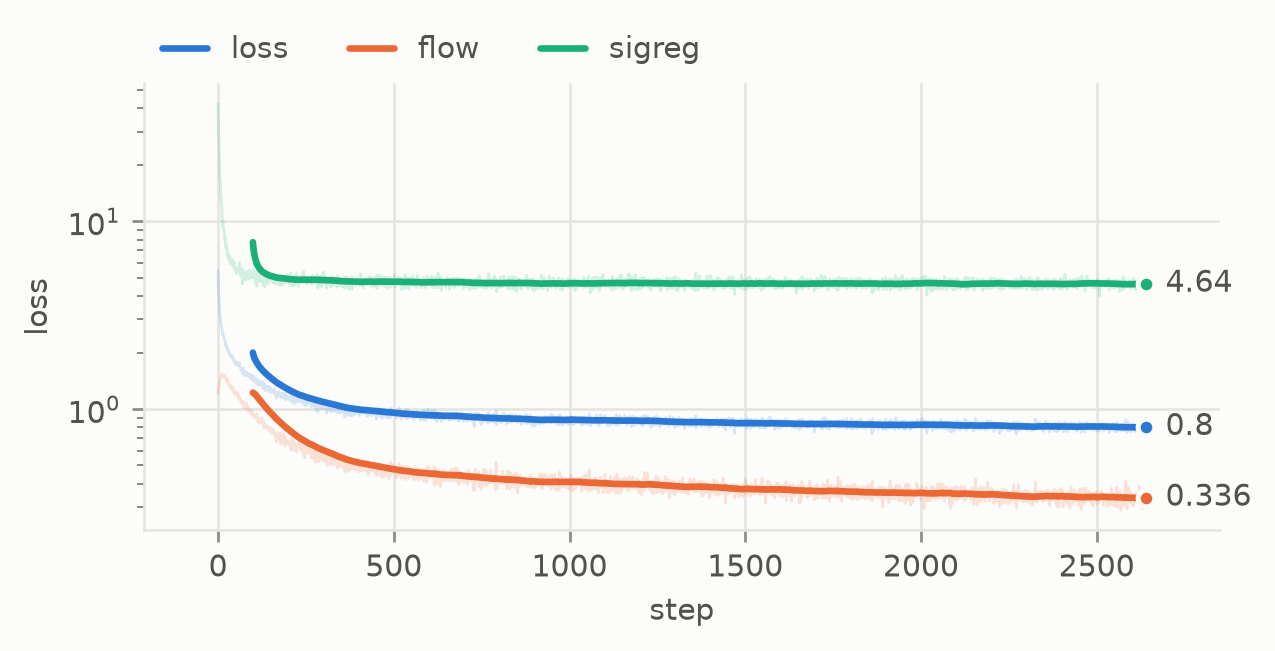

In [4]:
log = fit(model, loader, epochs=30, lr=3e-4, clip=1.0)
plots.curves(log, smooth=100)

## Several futures from one state
Push the macaw right for 25 steps and draw 16 futures each time. In front of the gap, whether it passes depends on exactly where it is, so the futures should spread more than in front of the rock, where the push just runs into it.

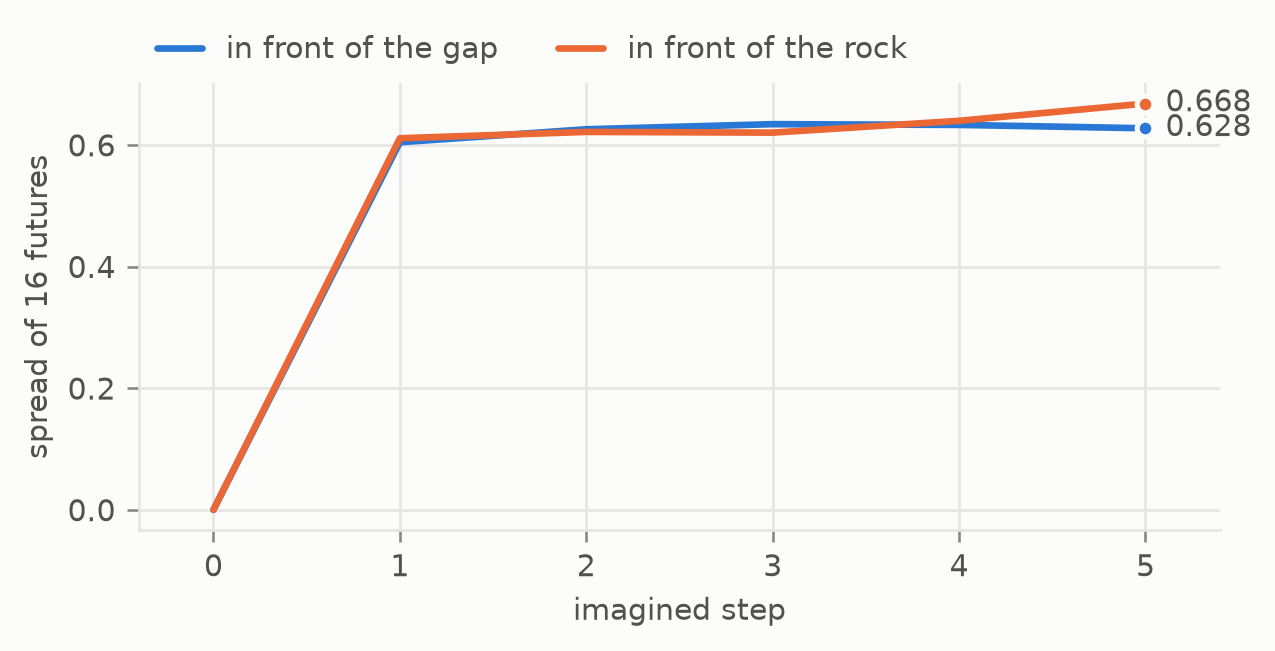

In [5]:
starts = {
    "in front of the gap": torch.stack([torch.full((64,), 0.35), torch.linspace(0.38, 0.62, 64)], -1),
    "in front of the rock": torch.stack([torch.full((64,), 0.35), torch.linspace(0.15, 0.28, 64)], -1),
}
push = torch.tensor([1.0, 0.0], device=device).repeat(64, 5, SKIP)  # (64, 5 steps, 10)
spread = {}
for name, start in starts.items():
    with torch.no_grad():
        z = model.encode(Macaw(rooms=True).render(start)[:, None].to(device))
        futures = model.sample(z, push, num_samples=16)  # (64, 16, 6, embed_dim)
    spread[name] = (range(6), futures.std(1).mean((0, 2)).tolist())
plots.curves(spread, smooth=1, logy=False, xlabel="imagined step", ylabel="spread of 16 futures")

## Plan toward goal images across the wall
CEM searches 5 chunks of 5 actions, scoring each candidate on one sampled future; the policy runs the first chunk and plans again.

In [6]:
env = Macaw(batch_size=32, rooms=True, device=device)
start, goal = env.tasks(generator=torch.Generator().manual_seed(1))  # start and goal on opposite sides of the wall
goal_images = env.render(goal)

planner = CEM(horizon=5, action_dim=2 * SKIP, num_samples=300, num_elites=30, bounds=(-1, 1))
policies = {
    "Flow-JEPA + CEM": evaluation.goal_policy(model, planner, goal_images, action_dim=2),
    "random actions": evaluation.random_policy(env),
}
result = evaluation.goal_reaching(env, policies, start, goal, steps=50, success="reached")
result

                           success  reached   steps  final distance  progress     SPL  smoothness  ms / step
Flow-JEPA + CEM     66% [48%, 80%]      66%    25.1           0.163     0.684   0.211       0.411   2.23e+03
random actions       12% [5%, 28%]      12%      31           0.454    0.0573  0.0145        1.05     0.0413

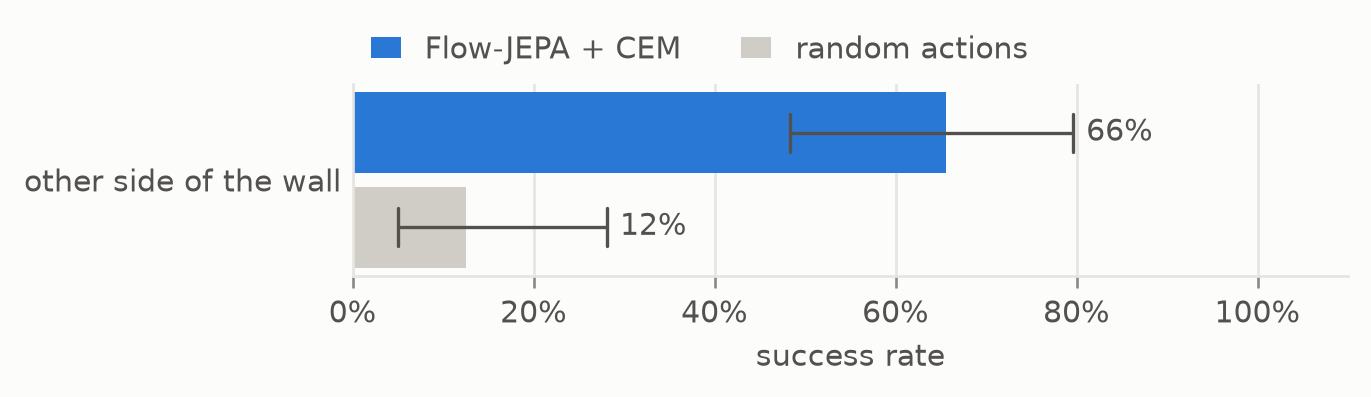

In [7]:
plots.bars({"other side of the wall": result.intervals()}, xlabel="success rate", baseline="random actions")

## Summary
Flow-JEPA learns a distribution over latent futures instead of a single guess, end to end from pixels. Sampling shows where the model is unsure; CEM plans on sampled futures with no change to the planner.